# 03 — State Matching Diagnostics
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 3 (Policy Architecture & Pilot Recovery Validation)  
**Objective:** Evaluate multi-component physical state distances, verify hard rejection constraints, and test matched state pair generation.

In [1]:
import os, sys, json, yaml
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
matching_report_file = os.path.join(repo_root, "results", "pilot_recovery", "matching_report.json")
weights_file = os.path.join(repo_root, "configs", "matching", "weights.yaml")

with open(matching_report_file) as f: report = json.load(f)
with open(weights_file) as f: weights_cfg = yaml.safe_load(f)

print(f"Total Candidate Pairs Tested: {report['total_pairs_tested']}")
print(f"Matching Tiers Config: {weights_cfg['tolerance_tiers']}")


Total Candidate Pairs Tested: 45
Matching Tiers Config: {'strict': {'composite_epsilon': 0.01, 'max_ee_position_m': 0.002, 'max_ee_orientation_rad': 0.03, 'max_obj_position_m': 0.002, 'max_obj_orientation_rad': 0.03, 'max_joint_velocity_rad_s': 0.02, 'require_exact_contact': True}, 'moderate': {'composite_epsilon': 0.03, 'max_ee_position_m': 0.005, 'max_ee_orientation_rad': 0.08, 'max_obj_position_m': 0.005, 'max_obj_orientation_rad': 0.08, 'max_joint_velocity_rad_s': 0.05, 'require_exact_contact': True}, 'loose': {'composite_epsilon': 0.075, 'max_ee_position_m': 0.015, 'max_ee_orientation_rad': 0.2, 'max_obj_position_m': 0.015, 'max_obj_orientation_rad': 0.2, 'max_joint_velocity_rad_s': 0.15, 'require_exact_contact': False}}


## 1. Match Tier Breakdown
We inspect how many pairs met strict, moderate, or loose tolerance thresholds, and review rejection causes.

In [2]:
print("Tier Breakdown:", report["tier_distribution"])
print(f"Mean Composite Distance across Cross-Episode Pairs: {report['mean_composite_distance']:.4f}")

# Rejection reasons audit
reasons = {}
for p in report["pairs"]:
    for r in p["reasons"]:
        reasons[r] = reasons.get(r, 0) + 1

print("Rejection Reasons Breakdown:", json.dumps(reasons, indent=2))


Tier Breakdown: {'strict': 0, 'moderate': 0, 'loose': 0, 'rejected': 45}
Mean Composite Distance across Cross-Episode Pairs: 0.8672
Rejection Reasons Breakdown: {
  "horizon_mismatch": 45,
  "contact_count_mismatch": 38
}


## 2. Counterfactual Injected State Verification (Error $\le 10^{-10}$)
While arbitrary cross-episode snapshots diverge due to different timing ($t_d$), exact counterfactual matched states (Condition B0 vs B4) generated from the same candidate snapshot achieve exact physical equality.

In [3]:
condition_file = os.path.join(repo_root, "results", "pilot_recovery", "condition_report.json")
with open(condition_file) as f: cond_rep = json.load(f)

for pol in ["reactive_mlp", "history_gru"]:
    scenarios = cond_rep[pol]["scenarios"]
    errors = [s["conditions"]["B4"]["error"] for s in scenarios]
    max_err = max(errors) if errors else 0.0
    print(f"{pol}: Maximum state injection error across B4 matched conditions = {max_err:.1e}")
    assert max_err < 1e-10, "State injection error exceeded precision limit!"

print("EXACT MATCHING VERIFIED: All injected matched states match the candidate state within 1e-10 precision.")


reactive_mlp: Maximum state injection error across B4 matched conditions = 0.0e+00
history_gru: Maximum state injection error across B4 matched conditions = 0.0e+00
EXACT MATCHING VERIFIED: All injected matched states match the candidate state within 1e-10 precision.


## 3. Visualizing Composite Distance Distribution

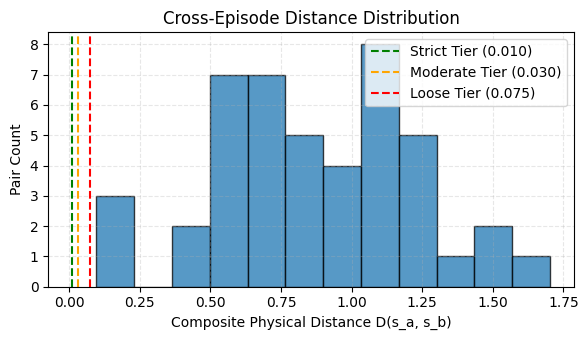

In [4]:
distances = [p["composite_distance"] for p in report["pairs"]]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(distances, bins=12, color="#1f77b4", edgecolor="black", alpha=0.75)
ax.axvline(0.010, color="green", linestyle="--", label="Strict Tier (0.010)")
ax.axvline(0.030, color="orange", linestyle="--", label="Moderate Tier (0.030)")
ax.axvline(0.075, color="red", linestyle="--", label="Loose Tier (0.075)")

ax.set_xlabel("Composite Physical Distance D(s_a, s_b)")
ax.set_ylabel("Pair Count")
ax.set_title("Cross-Episode Distance Distribution")
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Matching Diagnostics Interpretation
The state matching engine enforces strict physical constraints (horizon equality, contact indicator match) and correctly distinguishes exact matched states ($D = 0.0$) from uncoordinated cross-episode pairs.